<a href="https://colab.research.google.com/github/Ramandeep-Singh17/College_Research_Project/blob/main/BrainTumorExplainableAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
import os

os.makedirs("/root/.kaggle", exist_ok=True)

!cp kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json
!pip -q install kaggle

In [ ]:
!kaggle datasets list -s "brain tumor mri"

ref                                                        title                                             size  lastUpdated                 downloadCount  voteCount  usabilityRating  
---------------------------------------------------------  ------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
masoudnickparvar/brain-tumor-mri-dataset                   Brain Tumor MRI Dataset                      164670110  2026-02-13 19:25:36.413000         218252       1491  0.875            
sartajbhuvaji/brain-tumor-classification-mri               Brain Tumor Classification (MRI)              91002358  2025-08-12 15:45:16.840000         104935        871  0.875            
navoneel/brain-mri-images-for-brain-tumor-detection        Brain MRI Images for Brain Tumor Detection    15828590  2019-04-14 15:15:54.730000         168670       1653  0.5              
rm1000/brain-tumor-mri-scans                               Brain 

In [ ]:
!kaggle datasets download \
    -d masoudnickparvar/brain-tumor-mri-dataset \
    -p /content/data

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:00<00:00, 256MB/s]



In [ ]:
import zipfile
import os

zip_path = "/content/data/brain-tumor-mri-dataset.zip"
extract_path = "/content/brain_tumor"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['Testing', 'Training']


In [ ]:
for root, dirs, files in os.walk(extract_path):
    if dirs and any(
        name.lower() in ["glioma", "meningioma", "pituitary", "notumor"]
        for name in dirs
    ):
        print("Dataset folder:", root)
        print("Classes:", dirs)

Dataset folder: /content/brain_tumor/Testing
Classes: ['meningioma', 'glioma', 'notumor', 'pituitary']
Dataset folder: /content/brain_tumor/Training
Classes: ['meningioma', 'glioma', 'notumor', 'pituitary']


# Step 4 — Dataset inspect karo

In [ ]:
import os

base_path = "/content/brain_tumor"
classes = ["glioma", "meningioma", "notumor", "pituitary"]

for split in ["Training", "Testing"]:
    print(f"\n{split} Dataset:")
    total = 0

    for cls in classes:
        folder = os.path.join(base_path, split, cls)

        count = sum(
            1 for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        )

        print(f"{cls}: {count}")
        total += count

    print("Total images:", total)


Training Dataset:
glioma: 1400
meningioma: 1400
notumor: 1400
pituitary: 1400
Total images: 5600

Testing Dataset:
glioma: 400
meningioma: 400
notumor: 400
pituitary: 400
Total images: 1600


# Step 5 — MRI images visualize karo

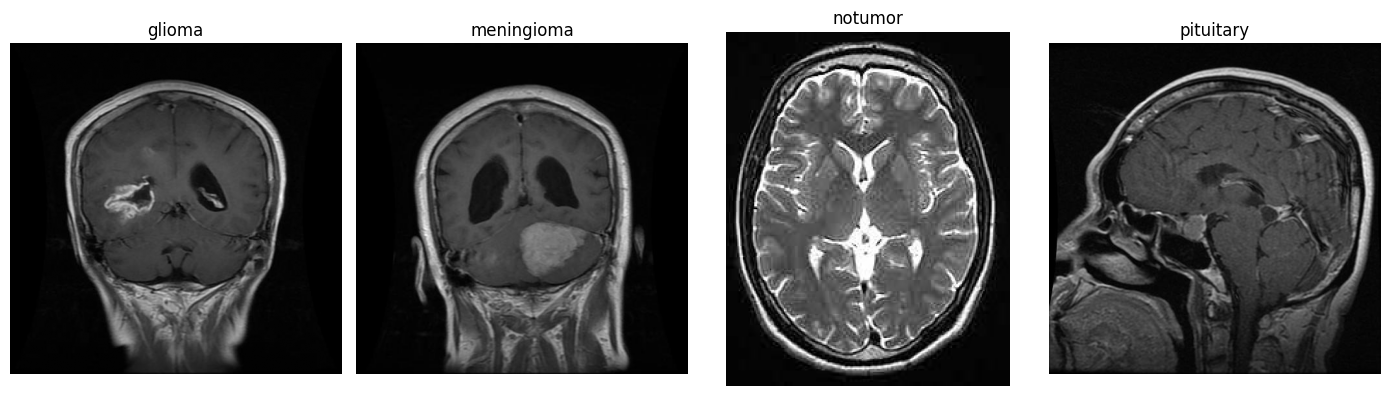

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

base_path = "/content/brain_tumor"
classes = ["glioma", "meningioma", "notumor", "pituitary"]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for i, cls in enumerate(classes):
    folder = os.path.join(base_path, "Training", cls)

    image_name = next(
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    )

    image_path = os.path.join(folder, image_name)
    img = Image.open(image_path)

    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(cls)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# Image quality + duplicate check

In [ ]:
import os
from PIL import Image
from collections import Counter

base_path = "/content/brain_tumor"
extensions = (".jpg", ".jpeg", ".png", ".bmp")

for split in ["Training", "Testing"]:
    sizes = Counter()
    modes = Counter()

    for cls in os.listdir(os.path.join(base_path, split)):
        folder = os.path.join(base_path, split, cls)

        for name in os.listdir(folder):
            if name.lower().endswith(extensions):
                path = os.path.join(folder, name)

                try:
                    with Image.open(path) as img:
                        sizes[img.size] += 1
                        modes[img.mode] += 1
                except Exception:
                    print("Unreadable image:", path)

    print(f"\n{split}")
    print("Most common dimensions:", sizes.most_common(5))
    print("Image modes:", modes)


Training
Most common dimensions: [((512, 512), 4012), ((225, 225), 253), ((630, 630), 69), ((201, 251), 40), ((236, 236), 39)]
Image modes: Counter({'RGB': 3238, 'L': 2358, 'RGBA': 3, 'P': 1})

Testing
Most common dimensions: [((512, 512), 1002), ((225, 225), 85), ((630, 630), 21), ((228, 221), 19), ((227, 222), 19)]
Image modes: Counter({'RGB': 891, 'L': 709})


# Step 6: Data leakage check

In [ ]:
import os
import hashlib
from collections import defaultdict

base_path = "/content/brain_tumor"
extensions = (".jpg", ".jpeg", ".png", ".bmp")

hash_locations = defaultdict(list)

for split in ["Training", "Testing"]:
    for cls in os.listdir(os.path.join(base_path, split)):
        folder = os.path.join(base_path, split, cls)

        for filename in os.listdir(folder):
            if not filename.lower().endswith(extensions):
                continue

            path = os.path.join(folder, filename)

            with open(path, "rb") as f:
                image_hash = hashlib.sha256(f.read()).hexdigest()

            hash_locations[image_hash].append((split, cls, filename))

cross_split_duplicates = []

for image_hash, locations in hash_locations.items():
    splits = {item[0] for item in locations}

    if len(splits) > 1:
        cross_split_duplicates.append(locations)

print("Total unique file hashes:", len(hash_locations))
print("Exact duplicates across Training/Testing:",
      len(cross_split_duplicates))

Total unique file hashes: 7013
Exact duplicates across Training/Testing: 0


# Step 7 — Internal duplicates check karo

In [ ]:
from collections import defaultdict
import os
import hashlib

base_path = "/content/brain_tumor"
hash_locations = defaultdict(list)

for split in ["Training", "Testing"]:
    for cls in os.listdir(os.path.join(base_path, split)):
        folder = os.path.join(base_path, split, cls)

        for filename in os.listdir(folder):
            if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                path = os.path.join(folder, filename)

                with open(path, "rb") as f:
                    h = hashlib.sha256(f.read()).hexdigest()

                hash_locations[h].append((split, cls, filename))

duplicates = {
    h: locations
    for h, locations in hash_locations.items()
    if len(locations) > 1
}

print("Duplicate hash groups:", len(duplicates))

for h, locations in list(duplicates.items())[:10]:
    print("\n", locations)

Duplicate hash groups: 153

 [('Training', 'meningioma', 'Tr-me_245.jpg'), ('Training', 'meningioma', 'Tr-aug-me_91.jpg')]

 [('Training', 'meningioma', 'Tr-me_1295.jpg'), ('Training', 'meningioma', 'Tr-aug-me_95.jpg')]

 [('Training', 'meningioma', 'Tr-aug-me_92.jpg'), ('Training', 'meningioma', 'Tr-me_268.jpg')]

 [('Training', 'meningioma', 'Tr-me_1274.jpg'), ('Training', 'meningioma', 'Tr-aug-me_98.jpg')]

 [('Training', 'meningioma', 'Tr-me_534.jpg'), ('Training', 'meningioma', 'Tr-me_339.jpg'), ('Training', 'meningioma', 'Tr-me_86.jpg')]

 [('Training', 'meningioma', 'Tr-me_532.jpg'), ('Training', 'meningioma', 'Tr-aug-me_97.jpg')]

 [('Training', 'meningioma', 'Tr-me_432.jpg'), ('Training', 'meningioma', 'Tr-me_561.jpg')]

 [('Training', 'meningioma', 'Tr-aug-me_89.jpg'), ('Training', 'meningioma', 'Tr-me_889.jpg')]

 [('Training', 'meningioma', 'Tr-me_1094.jpg'), ('Training', 'meningioma', 'Tr-me_219.jpg')]

 [('Training', 'meningioma', 'Tr-me_726.jpg'), ('Training', 'meningiom

# duplicates ka complete audit

In [ ]:
from collections import Counter

group_sizes = Counter()
cross_class_groups = []
cross_split_groups = []

for locations in duplicates.values():
    group_sizes[len(locations)] += 1

    classes = {x[1] for x in locations}
    splits = {x[0] for x in locations}

    if len(classes) > 1:
        cross_class_groups.append(locations)

    if len(splits) > 1:
        cross_split_groups.append(locations)

print("Duplicate groups by size:", dict(group_sizes))
print("Groups spanning multiple classes:", len(cross_class_groups))
print("Groups spanning Training and Testing:", len(cross_split_groups))

Duplicate groups by size: {2: 124, 3: 25, 4: 3, 5: 1}
Groups spanning multiple classes: 0
Groups spanning Training and Testing: 0


# Clean dataset prepare karna

In [ ]:
import os
import hashlib
import shutil

source = "/content/brain_tumor"
clean = "/content/brain_tumor_clean"
exts = (".jpg", ".jpeg", ".png", ".bmp")

os.makedirs(clean, exist_ok=True)

for split in ["Training", "Testing"]:
    seen = set()

    for cls in ["glioma", "meningioma", "notumor", "pituitary"]:
        src = os.path.join(source, split, cls)
        dst = os.path.join(clean, split, cls)
        os.makedirs(dst, exist_ok=True)

        for name in sorted(os.listdir(src)):
            if not name.lower().endswith(exts):
                continue

            path = os.path.join(src, name)

            with open(path, "rb") as f:
                h = hashlib.sha256(f.read()).hexdigest()

            if h in seen:
                continue

            seen.add(h)
            shutil.copy2(path, os.path.join(dst, name))

print("Cleaned dataset ready!")

Cleaned dataset ready!


In [ ]:
import os

clean = "/content/brain_tumor_clean"
classes = ["glioma", "meningioma", "notumor", "pituitary"]

for split in ["Training", "Testing"]:
    print(f"\n{split}")
    for cls in classes:
        folder = os.path.join(clean, split, cls)
        count = len(os.listdir(folder))
        print(f"{cls}: {count}")


Training
glioma: 1400
meningioma: 1386
notumor: 1281
pituitary: 1362

Testing
glioma: 386
meningioma: 398
notumor: 400
pituitary: 400


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

DATA_DIR = "/content/brain_tumor_clean/Training"
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Load image paths and labels
paths, labels = [], []

for label, cls in enumerate(CLASSES):
    folder = os.path.join(DATA_DIR, cls)

    for filename in sorted(os.listdir(folder)):
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            paths.append(os.path.join(folder, filename))
            labels.append(label)

paths = np.array(paths)
labels = np.array(labels)

# Stratified training/validation split
train_paths, val_paths, y_train, y_val = train_test_split(
    paths,
    labels,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

print("Training:", len(train_paths))
print("Validation:", len(val_paths))

# Decode, resize, and normalize images
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            len(paths), seed=SEED, reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_paths, y_train, training=True)
val_ds = make_dataset(val_paths, y_val)

# Custom CNN baseline
model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.30),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)


Training: 4343
Validation: 1086


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,828 (1.61 MB)

 Trainable params: 421,828 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 31s 145ms/step - accuracy: 0.4209 - loss: 1.1774 - val_accuracy: 0.5764 - val_loss: 0.9884 - learning_rate: 0.0010
Epoch 2/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step - accuracy: 0.5802 - loss: 0.9693 - val_accuracy: 0.6657 - val_loss: 0.8376 - learning_rate: 0.0010
Epoch 3/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 67ms/step - accuracy: 0.6493 - loss: 0.8595 - val_accuracy: 0.6722 - val_loss: 0.8255 - learning_rate: 0.0010
Epoch 4/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 67ms/step - accuracy: 0.6921 - loss: 0.7640 - val_accuracy: 0.7578 - val_loss: 0.6151 - learning_rate: 0.0010
Epoch 5/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 74ms/step - accuracy: 0.7315 - loss: 0.6806 - val_accuracy: 0.7744 - val_loss: 0.5799 - learning_rate: 0.0010
Epoch 6/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - accuracy: 0.7336 - loss: 0.6635 - val_accuracy: 0.8057 - val_loss: 0.5241 - learning_rate: 0.0010
Epoch 7/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - accuracy: 0.7651 - los

# Step 11 — Accuracy/Loss graphs aur Confusion Matrix

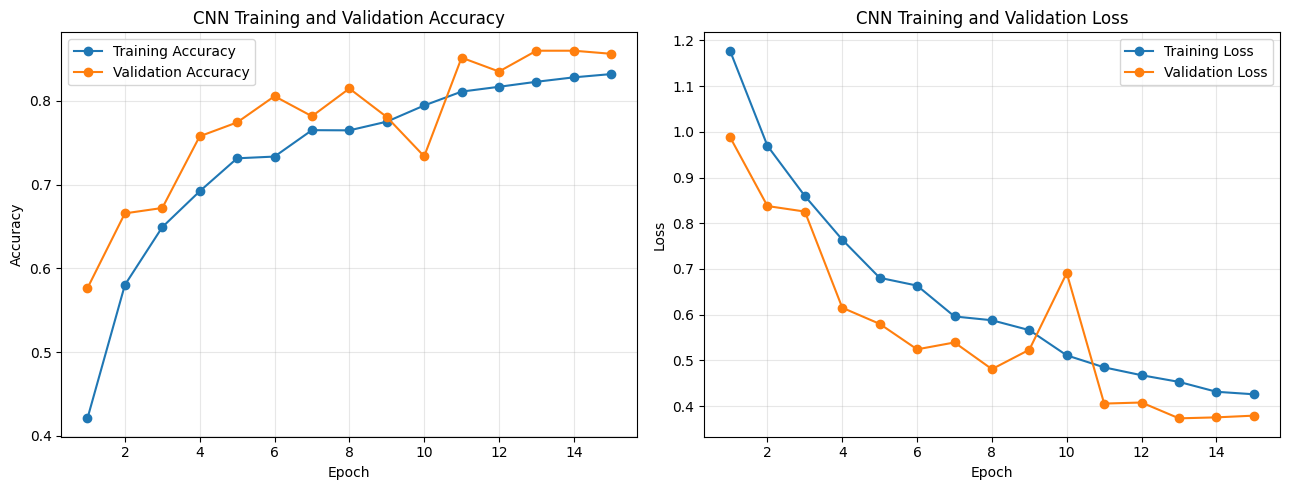

34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 156ms/step
Validation Classification Report:
              precision    recall  f1-score   support

      glioma     0.8534    0.8107    0.8315       280
  meningioma     0.7782    0.7473    0.7624       277
     notumor     0.9158    0.9766    0.9452       256
   pituitary     0.8897    0.9158    0.9025       273

    accuracy                         0.8600      1086
   macro avg     0.8593    0.8626    0.8604      1086
weighted avg     0.8580    0.8600    0.8585      1086



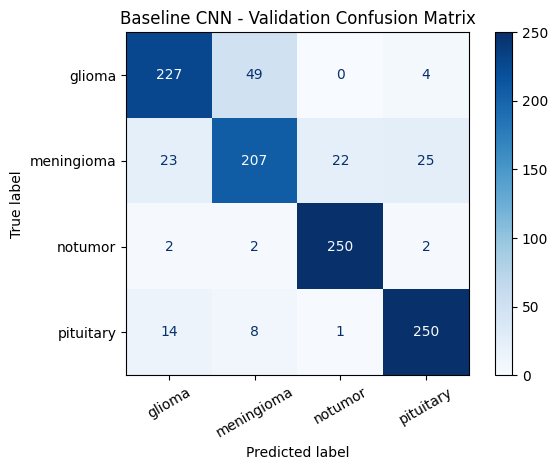

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Accuracy and loss curves
epochs = range(1, len(history.history["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(epochs, history.history["accuracy"], marker="o",
             label="Training Accuracy")
axes[0].plot(epochs, history.history["val_accuracy"], marker="o",
             label="Validation Accuracy")
axes[0].set_title("CNN Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs, history.history["loss"], marker="o",
             label="Training Loss")
axes[1].plot(epochs, history.history["val_loss"], marker="o",
             label="Validation Loss")
axes[1].set_title("CNN Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("baseline_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Predictions on validation data only
y_prob = model.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

# 3. Classification report
print("Validation Classification Report:")
print(classification_report(
    y_val,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=CLASSES,
    digits=4,
    zero_division=0
))

# 4. Confusion matrix
cm = confusion_matrix(y_val, y_pred, labels=[0, 1, 2, 3])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Baseline CNN - Validation Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("baseline_validation_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()


# ResNet50 Transfer Learning

In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Rebuild datasets for ResNet50.
# ResNet preprocessing expects pixel values in the 0-255 range.
def load_resnet_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32)
    return image, label

def make_resnet_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            len(paths), seed=42, reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_resnet_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)

train_ds_resnet = make_resnet_dataset(
    train_paths, y_train, training=True
)
val_ds_resnet = make_resnet_dataset(val_paths, y_val)

# Load pretrained ResNet50 without its original classification head
base_model = keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# First train only the new classification head
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = layers.Rescaling(1.0 / 127.5, offset=-1)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(4, activation="softmax")(x)

resnet_model = keras.Model(inputs, outputs)

resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

resnet_history = resnet_model.fit(
    train_ds_resnet,
    validation_data=val_ds_resnet,
    epochs=8,
    callbacks=resnet_callbacks
)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
136/136 ━━━━━━━━━━━━━━━━━━━━ 48s 245ms/step - accuracy: 0.5533 - loss: 1.0304 - val_accuracy: 0.7256 - val_loss: 0.7287 - learning_rate: 0.0010
Epoch 2/8
136/136 ━━━━━━━━━━━━━━━━━━━━ 22s 159ms/step - accuracy: 0.6647 - loss: 0.8066 - val_accuracy: 0.7136 - val_loss: 0.7057 - learning_rate: 0.0010
Epoch 3/8
136/136 ━━━━━━━━━━━━━━━━━━━━ 20s 144ms/step - accuracy: 0.6804 - loss: 0.7460 - val_accuracy: 0.7606 - val_loss: 0.6008 - learning_rate: 0.0010
Epoch 4/8
136/136 ━━━━━━━━━━━━━━━━━━━━ 19s 141ms/step - accuracy: 0.7096 - loss: 0.6993 - val_accuracy: 0.7873 - val_loss: 0.5786 - learning_rate: 0.0010
Epoch 5/8
136/136 ━━━━━━━━━━━━━━━━━━━━ 19s 143ms/step - accuracy: 0.7359 - loss: 0.6555 - val_accuracy: 0.7818 - val_loss: 0.5587 - learning_rate: 0.0010
Epoch 6/8
136/136 ━━━━━━━━━━━━━━━━━━━━ 20s 145ms/step - accuracy: 0.7451 - loss: 0.6387 - val_accuracy: 0.7910 - val_loss: 0.5416 - learning_rate: 0.0010
Epoch 7/8
136/136 ━━━━━━━

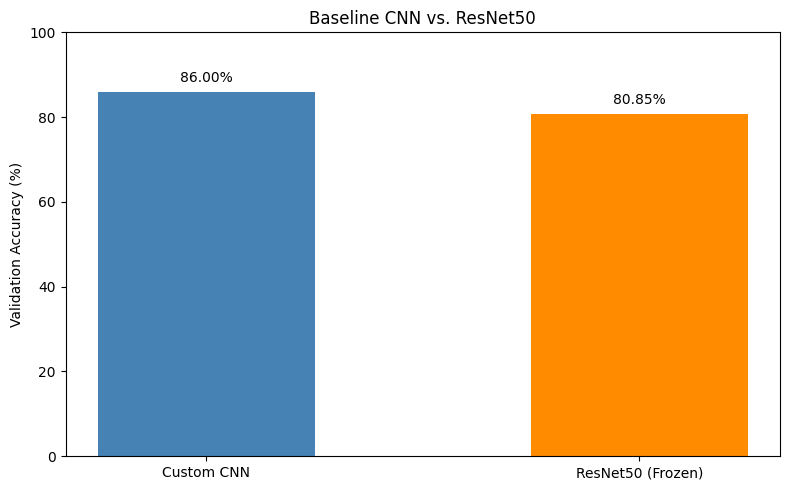

Accuracy difference: 5.15 percentage points


In [ ]:

import matplotlib.pyplot as plt

models = ["Custom CNN", "ResNet50 (Frozen)"]
accuracies = [86.00, 80.85]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    models,
    accuracies,
    width=0.5,
    color=["steelblue", "darkorange"]
)

plt.ylim(0, 100)
plt.ylabel("Validation Accuracy (%)")
plt.title("Baseline CNN vs. ResNet50")
plt.bar_label(bars, fmt="%.2f%%", padding=5)

plt.tight_layout()
plt.savefig(
    "cnn_vs_resnet50_validation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"Accuracy difference: {accuracies[0] - accuracies[1]:.2f} percentage points")


In [ ]:

# Unfreeze the last part of ResNet50 for fine-tuning.
base_model.trainable = True

# Keep most pretrained layers frozen; fine-tune only the final 30 layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for more stable fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7
    )
]

fine_tune_history = resnet_model.fit(
    train_ds_resnet,
    validation_data=val_ds_resnet,
    epochs=8,
    callbacks=fine_tune_callbacks
)


Epoch 1/8
136/136 ━━━━━━━━━━━━━━━━━━━━ 57s 282ms/step - accuracy: 0.7734 - loss: 0.5470 - val_accuracy: 0.8057 - val_loss: 0.4800 - learning_rate: 1.0000e-05
Epoch 2/8
136/136 ━━━━━━━━━━━━━━━━━━━━ 60s 179ms/step - accuracy: 0.8144 - loss: 0.4607 - val_accuracy: 0.8389 - val_loss: 0.4219 - learning_rate: 1.0000e-05
Epoch 3/8
136/136 ━━━━━━━━━━━━━━━━━━━━ 26s 190ms/step - accuracy: 0.8420 - loss: 0.3941 - val_accuracy: 0.8600 - val_loss: 0.3698 - learning_rate: 1.0000e-05
Epoch 4/8
136/136 ━━━━━━━━━━━━━━━━━━━━ 25s 184ms/step - accuracy: 0.8598 - loss: 0.3463 - val_accuracy: 0.8573 - val_loss: 0.3668 - learning_rate: 1.0000e-05
Epoch 5/8
136/136 ━━━━━━━━━━━━━━━━━━━━ 23s 170ms/step - accuracy: 0.8789 - loss: 0.3014 - val_accuracy: 0.8527 - val_loss: 0.3769 - learning_rate: 1.0000e-05
Epoch 6/8
136/136 ━━━━━━━━━━━━━━━━━━━━ 24s 178ms/step - accuracy: 0.8957 - loss: 0.2714 - val_accuracy: 0.8674 - val_loss: 0.3587 - learning_rate: 1.0000e-05
Epoch 7/8
136/136 ━━━━━━━━━━━━━━━━━━━━ 24s 179ms/ste

#Colab mein updated comparison graph

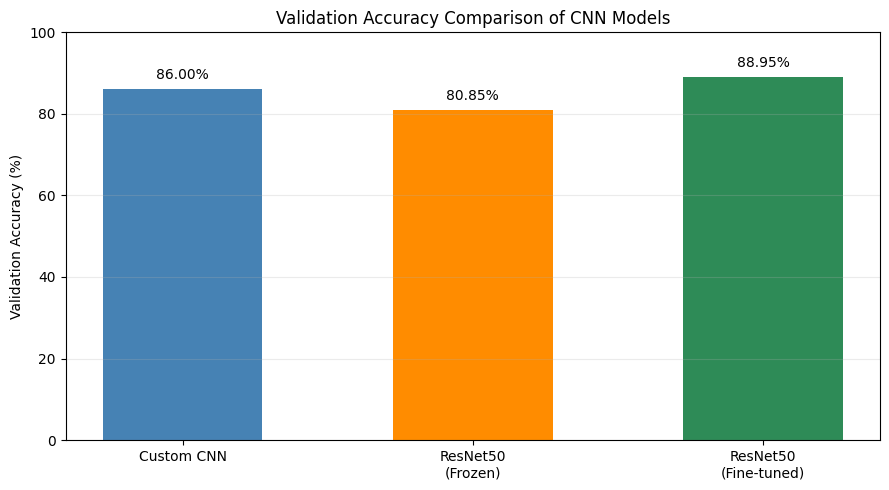

Fine-tuned ResNet50 vs Custom CNN: 2.95 percentage points


In [ ]:

import matplotlib.pyplot as plt

model_names = [
    "Custom CNN",
    "ResNet50\n(Frozen)",
    "ResNet50\n(Fine-tuned)"
]

accuracies = [86.00, 80.85, 88.95]

plt.figure(figsize=(9, 5))
bars = plt.bar(
    model_names,
    accuracies,
    width=0.55,
    color=["steelblue", "darkorange", "seagreen"]
)

plt.ylim(0, 100)
plt.ylabel("Validation Accuracy (%)")
plt.title("Validation Accuracy Comparison of CNN Models")
plt.bar_label(bars, fmt="%.2f%%", padding=5)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    "model_comparison_validation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Fine-tuned ResNet50 vs Custom CNN:",
      f"{88.95 - 86.00:.2f} percentage points")


In [ ]:

resnet_model.save("/content/resnet50_finetuned.keras")
print("Fine-tuned ResNet50 saved successfully.")


Fine-tuned ResNet50 saved successfully.


34/34 ━━━━━━━━━━━━━━━━━━━━ 17s 209ms/step
              precision    recall  f1-score   support

      glioma     0.8199    0.9107    0.8629       280
  meningioma     0.8290    0.8051    0.8168       277
     notumor     0.9637    0.9336    0.9484       256
   pituitary     0.9651    0.9121    0.9379       273

    accuracy                         0.8895      1086
   macro avg     0.8944    0.8904    0.8915      1086
weighted avg     0.8926    0.8895    0.8902      1086



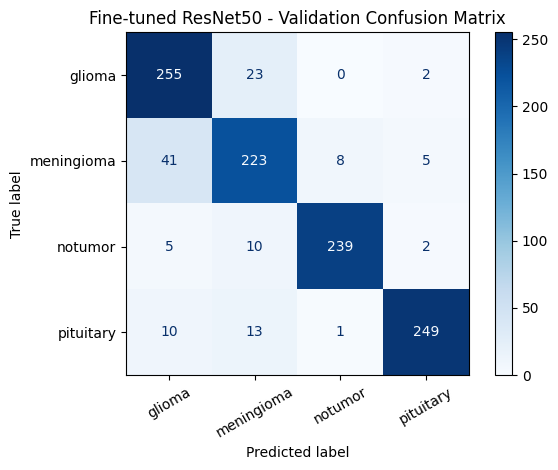

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_prob_resnet = resnet_model.predict(val_ds_resnet)
y_pred_resnet = np.argmax(y_prob_resnet, axis=1)

print(classification_report(
    y_val,
    y_pred_resnet,
    labels=[0, 1, 2, 3],
    target_names=CLASSES,
    digits=4,
    zero_division=0
))

cm_resnet = confusion_matrix(
    y_val, y_pred_resnet, labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_resnet,
    display_labels=CLASSES
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Fine-tuned ResNet50 - Validation Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(
    "resnet50_validation_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


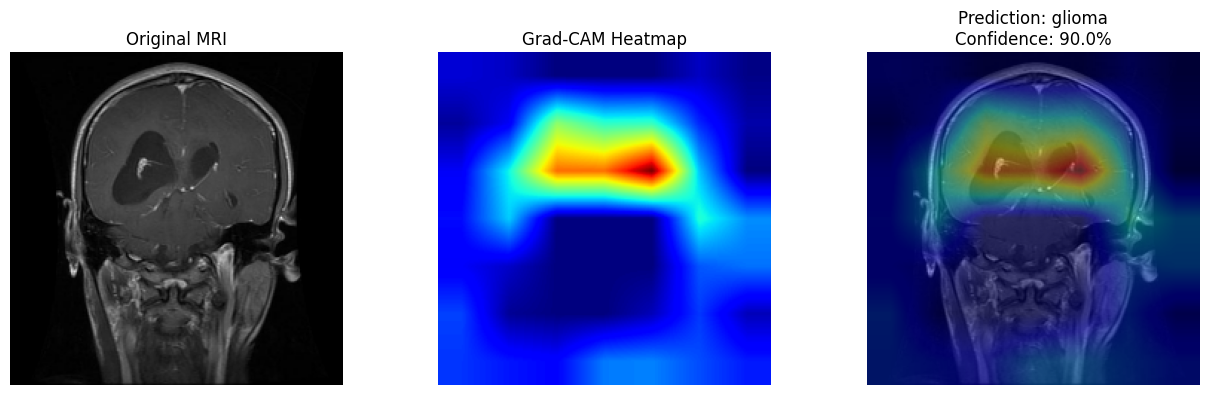

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

# Find the trained ResNet50 backbone
backbone = resnet_model.get_layer("resnet50")
last_conv_layer = "conv5_block3_out"

# Create a connected model exposing the final convolutional features
backbone_cam = keras.Model(
    inputs=backbone.input,
    outputs=[
        backbone.get_layer(last_conv_layer).output,
        backbone.output
    ]
)

# Rebuild the prediction path using the SAME trained layers
inputs = keras.Input(shape=(224, 224, 3))
x = resnet_model.layers[1](inputs)  # Rescaling layer

conv_outputs, backbone_features = backbone_cam(x, training=False)

x = backbone_features
for layer in resnet_model.layers[3:]:
    x = layer(x)

grad_model = keras.Model(
    inputs=inputs,
    outputs=[conv_outputs, x]
)

def make_gradcam(image_path):
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32)

    batch = tf.expand_dims(image, axis=0)

    with tf.GradientTape() as tape:
        conv_features, predictions = grad_model(
            batch, training=False
        )
        class_index = tf.argmax(predictions[0])
        class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, conv_features)

    if gradients is None:
        raise ValueError(
            "Gradients unavailable. Check model connectivity."
        )

    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
    conv_features = conv_features[0]

    heatmap = tf.reduce_sum(
        conv_features * weights, axis=-1
    )
    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + 1e-8

    return (
        image.numpy().astype("uint8"),
        heatmap.numpy(),
        int(class_index.numpy()),
        predictions.numpy()[0]
    )

# Generate Grad-CAM for one validation image
sample_path = val_paths[0]

original_image, heatmap, predicted_index, probabilities = make_gradcam(
    sample_path
)

heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis], (224, 224)
).numpy().squeeze()

plt.figure(figsize=(13, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original_image)
plt.imshow(heatmap_resized, cmap="jet", alpha=0.4)
plt.title(
    f"Prediction: {CLASSES[predicted_index]}\n"
    f"Confidence: {probabilities[predicted_index]:.1%}"
)
plt.axis("off")

plt.tight_layout()
plt.savefig(
    "gradcam_validation_example.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Explainable AI output

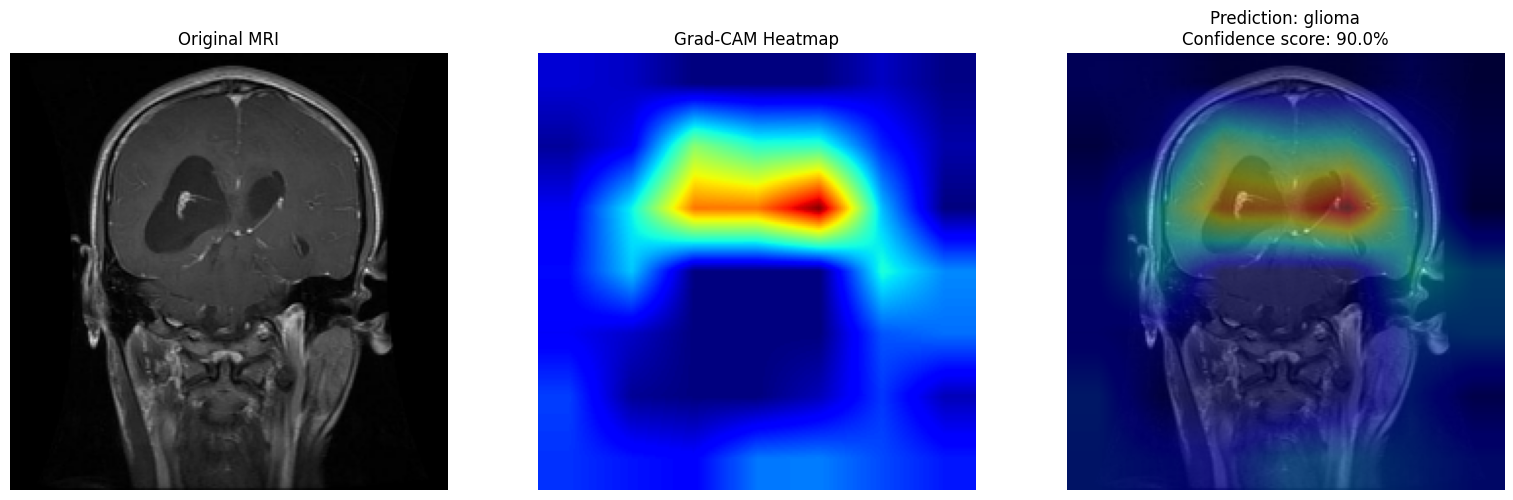

EXPLAINABLE AI REPORT
Predicted class: glioma
Model confidence score: 90.0%
Second prediction: meningioma (10.0%)
Confidence gap: 80.0%

Why this prediction? (model-based visual evidence)
The model predicted glioma. The Grad-CAM map shows the strongest average activation in the middle third of the displayed image. This describes where the model's class-specific activation is concentrated; it does not establish a clinical reason or prove that a tumor is present.

Grad-CAM activation distribution by image region:
  Upper third: 34.1%
  Middle third: 43.3%
  Lower third: 22.6%

Note: Confidence is not a measure of clinical certainty.
Grad-CAM highlights model-relevant image features, not
verified tumor boundaries or medically validated findings.


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Choose one validation image
sample_path = val_paths[0]

# Generate the existing Grad-CAM explanation
original_image, heatmap, predicted_index, probabilities = make_gradcam(
    sample_path
)

# Resize heatmap to original display dimensions
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis], (224, 224)
).numpy().squeeze()

# Rank predictions
ranking = np.argsort(probabilities)[::-1]
top_index = int(ranking[0])
second_index = int(ranking[1])

top_confidence = float(probabilities[top_index])
second_confidence = float(probabilities[second_index])

# Estimate how much of the heatmap activation lies in each region.
# These are image-region contributions, NOT anatomical diagnoses.
h, w = heatmap_resized.shape
regions = {
    "upper": heatmap_resized[:h//3, :],
    "middle": heatmap_resized[h//3:2*h//3, :],
    "lower": heatmap_resized[2*h//3:, :]
}

region_scores = {
    name: float(np.mean(region))
    for name, region in regions.items()
}

strongest_region = max(region_scores, key=region_scores.get)

# Normalize region scores for a descriptive summary
total_region_score = sum(region_scores.values()) + 1e-8
region_share = {
    name: score / total_region_score * 100
    for name, score in region_scores.items()
}

# Explanation text
explanation = (
    f"The model predicted {CLASSES[top_index]}. "
    f"The Grad-CAM map shows the strongest average activation "
    f"in the {strongest_region} third of the displayed image. "
    f"This describes where the model's class-specific activation "
    f"is concentrated; it does not establish a clinical reason "
    f"or prove that a tumor is present."
)

# Plot MRI, heatmap, overlay and prediction scores
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original MRI")
axes[0].axis("off")

axes[1].imshow(heatmap_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap")
axes[1].axis("off")

axes[2].imshow(original_image)
axes[2].imshow(heatmap_resized, cmap="jet", alpha=0.4,
               vmin=0, vmax=1)
axes[2].set_title(
    f"Prediction: {CLASSES[top_index]}\n"
    f"Confidence score: {top_confidence:.1%}"
)
axes[2].axis("off")

plt.tight_layout()
plt.savefig(
    "explainable_mri_visualization.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("=" * 55)
print("EXPLAINABLE AI REPORT")
print("=" * 55)
print(f"Predicted class: {CLASSES[top_index]}")
print(f"Model confidence score: {top_confidence:.1%}")
print(f"Second prediction: {CLASSES[second_index]} "
      f"({second_confidence:.1%})")
print(f"Confidence gap: {(top_confidence-second_confidence):.1%}")
print()
print("Why this prediction? (model-based visual evidence)")
print(explanation)
print()
print("Grad-CAM activation distribution by image region:")
for region, share in region_share.items():
    print(f"  {region.title()} third: {share:.1f}%")
print()
print("Note: Confidence is not a measure of clinical certainty.")
print("Grad-CAM highlights model-relevant image features, not")
print("verified tumor boundaries or medically validated findings.")


In [ ]:

import numpy as np
import tensorflow as tf

# Select 4 different validation images
num_examples = min(4, len(val_paths))
sample_paths = val_paths[:num_examples]

for i, sample_path in enumerate(sample_paths, start=1):

    # Use the Grad-CAM function already defined in Colab
    original_image, heatmap, predicted_index, probabilities = (
        make_gradcam(sample_path)
    )

    # Rank predicted classes
    ranking = np.argsort(probabilities)[::-1]
    top_idx = int(ranking[0])
    second_idx = int(ranking[1])

    confidence = float(probabilities[top_idx])
    second_confidence = float(probabilities[second_idx])
    gap = confidence - second_confidence

    # Resize heatmap and calculate activation by image thirds
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis], (224, 224)
    ).numpy().squeeze()

    h = heatmap_resized.shape[0]
    regions = {
        "upper": heatmap_resized[:h//3, :],
        "middle": heatmap_resized[h//3:2*h//3, :],
        "lower": heatmap_resized[2*h//3:, :]
    }

    region_strength = {
        name: float(np.mean(region))
        for name, region in regions.items()
    }
    strongest_region = max(region_strength, key=region_strength.get)

    print("\n" + "=" * 55)
    print(f"EXAMPLE {i}")
    print("=" * 55)
    print(f"Predicted class: {CLASSES[top_idx]}")
    print(f"Confidence score: {confidence:.2%}")
    print(f"Second choice: {CLASSES[second_idx]} "
          f"({second_confidence:.2%})")
    print(f"Score gap: {gap:.2%}")
    print(f"Strongest average Grad-CAM activation: "
          f"{strongest_region} third of image")

    print("\nExplanation:")
    print(
        f"The model ranked {CLASSES[top_idx]} first, with a score "
        f"of {confidence:.1%}. Its second choice was "
        f"{CLASSES[second_idx]} ({second_confidence:.1%}). "
        f"The Grad-CAM map showed its strongest average activation "
        f"in the {strongest_region} third of the displayed image. "
        "This describes model behavior, not a verified medical reason."
    )



EXAMPLE 1
Predicted class: glioma
Confidence score: 89.95%
Second choice: meningioma (10.00%)
Score gap: 79.95%
Strongest average Grad-CAM activation: middle third of image

Explanation:
The model ranked glioma first, with a score of 90.0%. Its second choice was meningioma (10.0%). The Grad-CAM map showed its strongest average activation in the middle third of the displayed image. This describes model behavior, not a verified medical reason.

EXAMPLE 2
Predicted class: pituitary
Confidence score: 99.94%
Second choice: meningioma (0.03%)
Score gap: 99.92%
Strongest average Grad-CAM activation: middle third of image

Explanation:
The model ranked pituitary first, with a score of 99.9%. Its second choice was meningioma (0.0%). The Grad-CAM map showed its strongest average activation in the middle third of the displayed image. This describes model behavior, not a verified medical reason.

EXAMPLE 3
Predicted class: pituitary
Confidence score: 91.34%
Second choice: meningioma (7.52%)
Score

In [ ]:

%pip -q install -U groq

from google.colab import userdata
from groq import Groq

api_key = userdata.get("GROQ_API_KEY")
assert api_key, "Secret missing or empty. Check the secret name and notebook access."

client = Groq(api_key=api_key)
print("Groq API key loaded successfully!")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 5.0 MB/s eta 0:00:00
Groq API key loaded successfully!


In [ ]:

import json
import numpy as np
import tensorflow as tf

# Friendly, evidence-grounded explanation instructions
SYSTEM_PROMPT = """
You are an Explainable AI assistant for a brain MRI
classification research project.

Explain the behavior of the model, not a patient's diagnosis.

Rules:
- Use only the supplied model scores and Grad-CAM measurements.
- Never invent tumor features, boundaries, symptoms, or anatomy.
- Model scores are not calibrated clinical probabilities.
- Grad-CAM highlights regions influential to a class score;
  it does not prove a tumor exists in that region.
- Upper, middle, and lower refer only to displayed image thirds.
- Clearly say when the evidence cannot establish the exact reason
  for a prediction.
- Use friendly, simple English and concise explanations.

Use these headings:
1. Prediction
2. What influenced the model?
3. What the heatmap shows
4. Alternative prediction
5. Limitations
"""

def explain_mri_with_groq(image_path):
    # Get actual outputs from your existing trained model
    image, heatmap, predicted_index, scores = make_gradcam(image_path)
    scores = np.asarray(scores, dtype=float)

    ranking = np.argsort(scores)[::-1]
    top_idx = int(ranking[0])
    second_idx = int(ranking[1])

    # Measure average Grad-CAM activation by displayed image thirds
    resized = tf.image.resize(
        heatmap[..., np.newaxis], (224, 224)
    ).numpy().squeeze()

    h = resized.shape[0]
    regions = {
        "upper third": resized[:h//3, :],
        "middle third": resized[h//3:2*h//3, :],
        "lower third": resized[2*h//3:, :]
    }

    activation = {
        name: float(np.mean(region))
        for name, region in regions.items()
    }

    evidence = {
        "predicted_class": CLASSES[top_idx],
        "top_class_score": round(float(scores[top_idx]), 4),
        "second_class": CLASSES[second_idx],
        "second_class_score": round(float(scores[second_idx]), 4),
        "score_gap": round(
            float(scores[top_idx] - scores[second_idx]), 4
        ),
        "mean_gradcam_activation_by_image_region": {
            name: round(value, 4)
            for name, value in activation.items()
        }
    }

    user_prompt = f"""
Explain this individual model output using only the evidence below.

{json.dumps(evidence, indent=2)}

Be specific to these measurements. Compare the top two scores.
Describe the strongest mean Grad-CAM activation region.
Do not claim that this region contains a tumor or proves a
medical reason for the classification. State what remains unknown.
"""

    response = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user_prompt}
        ],
        temperature=0.2,
        max_tokens=450
    )

    explanation = response.choices[0].message.content

    print("MODEL EVIDENCE")
    print(json.dumps(evidence, indent=2))
    print("\nGROQ EXPLANATION")
    print(explanation)

    return evidence, explanation, image, heatmap


# Test one validation MRI first
evidence, explanation, image, heatmap = explain_mri_with_groq(
    val_paths[0]
)


MODEL EVIDENCE
{
  "predicted_class": "glioma",
  "top_class_score": 0.8995,
  "second_class": "meningioma",
  "second_class_score": 0.1,
  "score_gap": 0.7995,
  "mean_gradcam_activation_by_image_region": {
    "upper third": 0.1814,
    "middle third": 0.2306,
    "lower third": 0.1205
  }
}

GROQ EXPLANATION
**1. Prediction**  
The model assigned the image to the class **glioma** with a score of **0.8995**. The next‑most likely class was **meningioma** with a score of **0.10**, giving a score gap of **0.7995**.

**2. What influenced the model?**  
The large difference between the glioma score (0.8995) and the meningioma score (0.10) shows that the model found the image much more consistent with patterns it has learned for glioma than for meningioma. The score gap of 0.7995 quantifies this confidence gap.

**3. What the heatmap shows**  
The Grad‑CAM heatmap reports the average activation in three vertical sections of the image:  

- Upper third: **0.1814**  
- **Middle third: 0.2306

In [ ]:

models = client.models.list()

available_models = sorted(
    model.id for model in models.data
    if "text" in getattr(model, "active", True).__str__().lower()
)

# Print model IDs only; no API key is exposed
for model in models.data:
    print(model.id)


allam-2-7b
openai/gpt-oss-120b
whisper-large-v3
openai/gpt-oss-20b
openai/gpt-oss-safeguard-20b
whisper-large-v3-turbo
meta-llama/llama-prompt-guard-2-86m
meta-llama/llama-prompt-guard-2-22m
canopylabs/orpheus-arabic-saudi
canopylabs/orpheus-v1-english
qwen/qwen3.8-27b


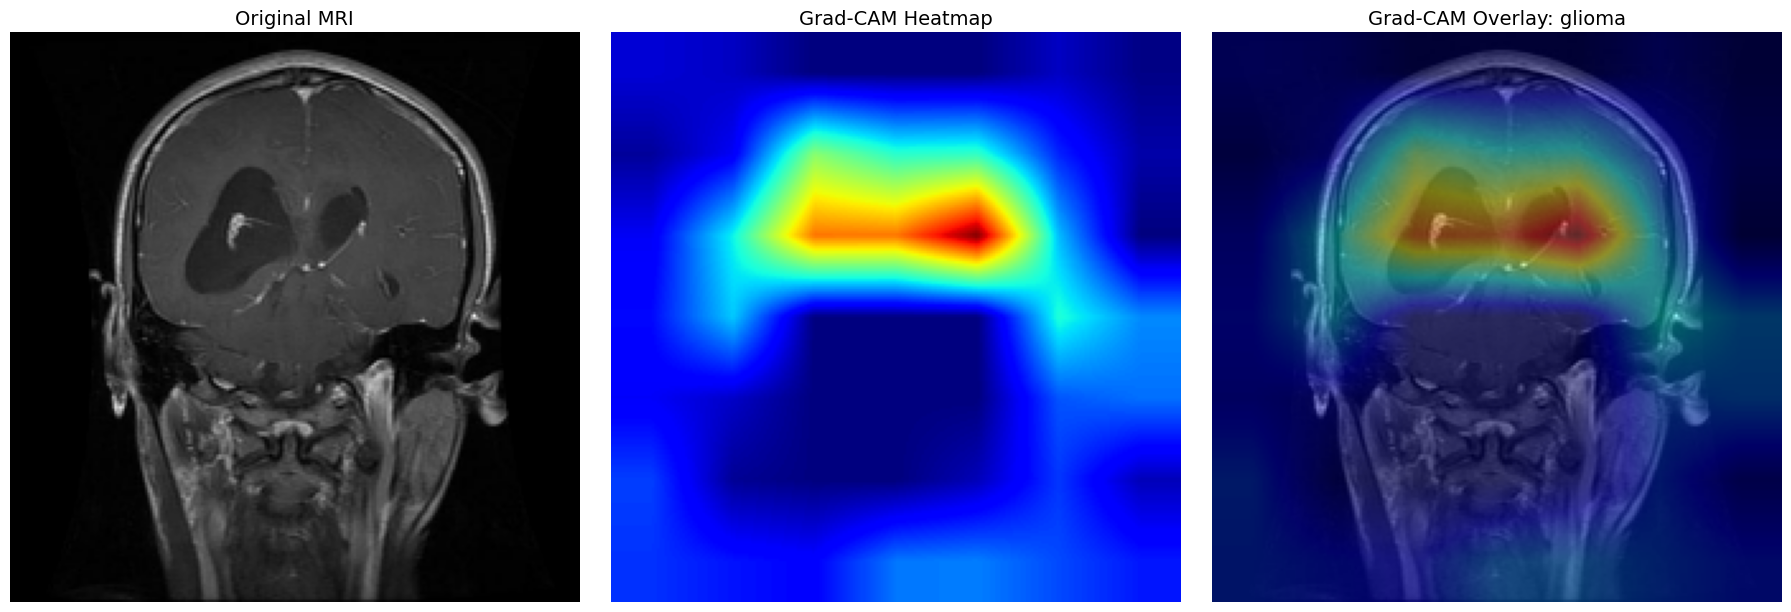

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

# Select a validation MRI image
image_path = val_paths[0]

# Generate Grad-CAM
image, heatmap, predicted_index, probabilities = make_gradcam(image_path)

# Resize heatmap to match MRI dimensions
heatmap_resized = cv2.resize(
    heatmap,
    (image.shape[1], image.shape[0])
)

# Convert heatmap to color
heatmap_uint8 = np.uint8(255 * heatmap_resized)
colored_heatmap = cv2.applyColorMap(
    heatmap_uint8, cv2.COLORMAP_JET
)
colored_heatmap = cv2.cvtColor(
    colored_heatmap, cv2.COLOR_BGR2RGB
)

# Prepare original MRI for visualization
display_image = np.uint8(
    np.clip(image, 0, 255)
)

# Blend MRI and heatmap
overlay = cv2.addWeighted(
    display_image, 0.6,
    colored_heatmap, 0.4, 0
)

# Plot results

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    constrained_layout=True
)

axes[0].imshow(display_image, cmap="gray")
axes[0].set_title("Original MRI", fontsize=14)
axes[0].axis("off")

axes[1].imshow(heatmap_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap", fontsize=14)
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title(
    f"Grad-CAM Overlay: {CLASSES[predicted_index]}",
    fontsize=14
)
axes[2].axis("off")

plt.show()



# Final panel ka code

MODEL EVIDENCE
{
  "predicted_class": "glioma",
  "top_class_score": 0.8995,
  "second_class": "meningioma",
  "second_class_score": 0.1,
  "score_gap": 0.7995,
  "mean_gradcam_activation_by_image_region": {
    "upper third": 0.1814,
    "middle third": 0.2306,
    "lower third": 0.1205
  }
}

GROQ EXPLANATION
**1. Prediction**  
The model’s highest‑scoring class is **glioma** with a score of **0.8995**. The next most likely class is **meningioma** with a score of **0.10**. The gap between them is **0.7995**, indicating the model is much more confident in glioma than in meningioma for this image.

**2. What influenced the model?**  
The model’s decision is driven by the patterns it has learned that raise the glioma score relative to other classes. The large score gap (0.7995) shows that, according to the model, the evidence supporting glioma is far stronger than the evidence for meningioma.

**3. What the heatmap shows**  
The Grad‑CAM heatmap reports the average activation in three v

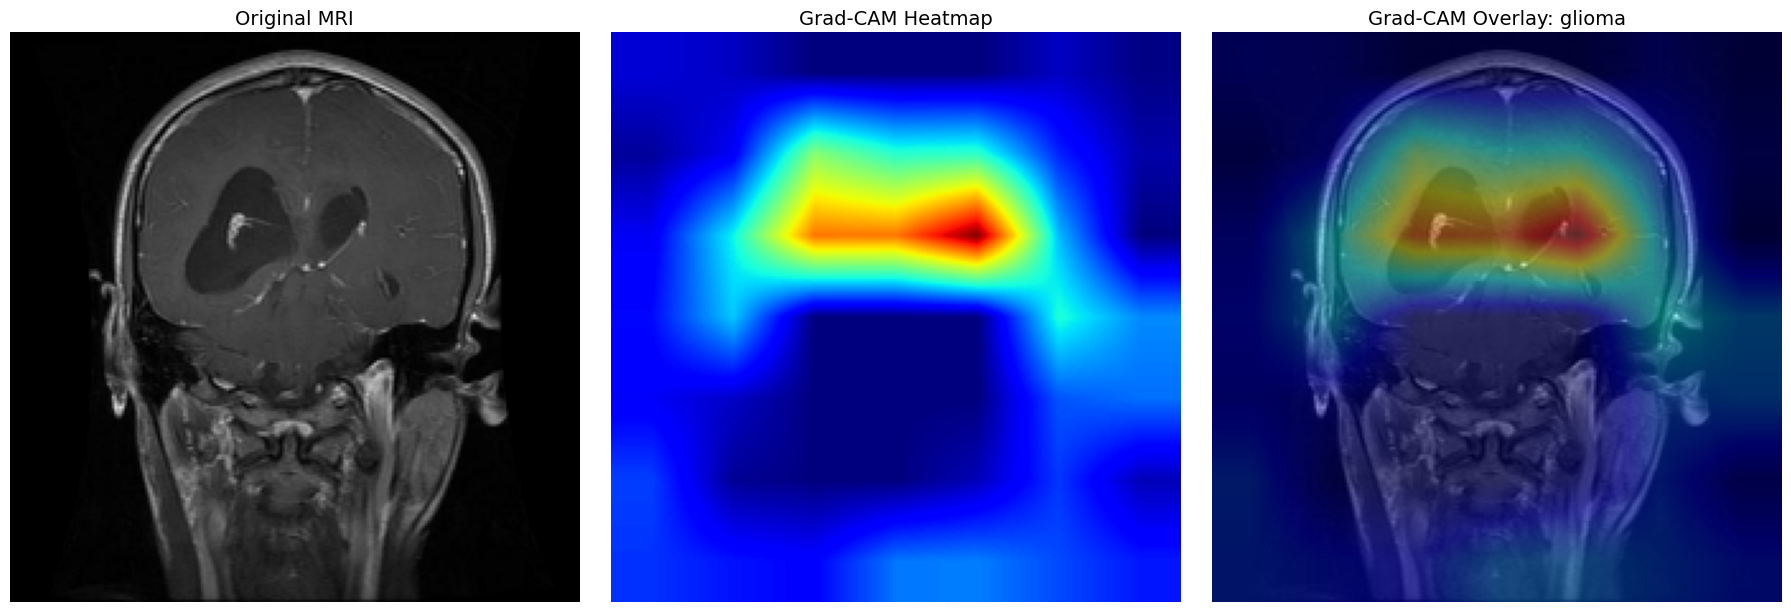

## Groq LLM Explanation

**1. Prediction**  
The model’s highest‑scoring class is **glioma** with a score of **0.8995**. The next most likely class is **meningioma** with a score of **0.10**. The gap between them is **0.7995**, indicating the model is much more confident in glioma than in meningioma for this image.

**2. What influenced the model?**  
The model’s decision is driven by the patterns it has learned that raise the glioma score relative to other classes. The large score gap (0.7995) shows that, according to the model, the evidence supporting glioma is far stronger than the evidence for meningioma.

**3. What the heatmap shows**  
The Grad‑CAM heatmap reports the average activation in three vertical sections of the image:

- Upper third: **0.1814**  
- **Middle third: 0.2306** (the highest)  
- Lower third: **0.1205**

The **middle third** has the strongest mean activation, meaning the model found the features in that region most influential for raising the glioma score.

**4. Alternative prediction**  
If the model had given a higher score to the second‑ranked class, the prediction would have been **meningioma**. However, its score (0.10) is far lower than the glioma score, so the model does not currently favor that alternative.

**5. Limitations**  
- The scores are **not calibrated clinical probabilities**; they only reflect the model’s internal confidence.  
- The Grad‑CAM heatmap

**Research disclaimer:** This is an experimental model prediction, not a medical diagnosis. Scores are not necessarily calibrated clinical probabilities, and Grad-CAM does not establish tumor presence or boundaries.

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import cv2
from IPython.display import display, Markdown

# 1. Select a validation MRI
image_path = val_paths[0]

# 2. Generate model prediction and Grad-CAM
image, heatmap, predicted_index, probabilities = make_gradcam(image_path)

# 3. Generate the Groq explanation using the same MRI
evidence, explanation, _, _ = explain_mri_with_groq(image_path)

# 4. Prepare image and heatmap
image_display = np.asarray(image)
image_display = np.clip(image_display, 0, 255).astype(np.uint8)

if image_display.ndim == 3 and image_display.shape[-1] == 1:
    image_display = image_display.squeeze(-1)

heatmap = np.asarray(heatmap).squeeze()
heatmap = np.maximum(heatmap, 0)
if heatmap.max() > 0:
    heatmap = heatmap / heatmap.max()

heatmap_resized = cv2.resize(
    heatmap.astype(np.float32),
    (image_display.shape[1], image_display.shape[0])
)

colored_heatmap = cv2.applyColorMap(
    np.uint8(255 * heatmap_resized),
    cv2.COLORMAP_JET
)
colored_heatmap = cv2.cvtColor(
    colored_heatmap, cv2.COLOR_BGR2RGB
)

if image_display.ndim == 2:
    image_rgb = cv2.cvtColor(image_display, cv2.COLOR_GRAY2RGB)
else:
    image_rgb = image_display[..., :3]

overlay = cv2.addWeighted(image_rgb, 0.60, colored_heatmap, 0.40, 0)

# 5. Display prediction and all class scores
scores = np.asarray(probabilities).reshape(-1)
if len(scores) != len(CLASSES):
    raise ValueError("Number of prediction scores does not match CLASSES.")

ranking = np.argsort(scores)[::-1]

print("=" * 55)
print("EXPLAINABLE BRAIN MRI CLASSIFICATION")
print("=" * 55)
print(f"Predicted class: {CLASSES[predicted_index]}")
print(f"Model score: {scores[predicted_index]:.4f}")
print("\nClass scores (highest to lowest):")

for idx in ranking:
    print(f"  {CLASSES[idx]:12s}: {scores[idx]:.4f}")

# 6. Show the three visualizations
fig, axes = plt.subplots(
    1, 3, figsize=(18, 6), constrained_layout=True
)

axes[0].imshow(image_rgb)
axes[0].set_title("Original MRI", fontsize=14)
axes[0].axis("off")

axes[1].imshow(heatmap_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap", fontsize=14)
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title(
    f"Grad-CAM Overlay: {CLASSES[predicted_index]}",
    fontsize=14
)
axes[2].axis("off")

plt.show()

# 7. Display the LLM explanation
display(Markdown("## Groq LLM Explanation"))
display(Markdown(str(explanation)))

display(Markdown(
    "**Research disclaimer:** This is an experimental model prediction, "
    "not a medical diagnosis. Scores are not necessarily calibrated "
    "clinical probabilities, and Grad-CAM does not establish tumor "
    "presence or boundaries."
))


# Explainable Brain MRI Classification

**Research prototype:** ResNet50 + Grad-CAM + Groq LLM

### Predicted class: `glioma`
**Model score:** 0.8995  
**Second-ranked class:** meningioma (0.1000)  
**Score gap:** 0.7995

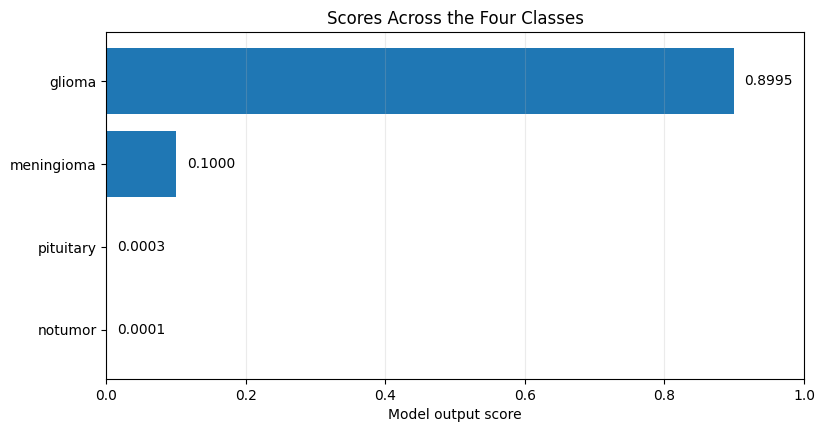

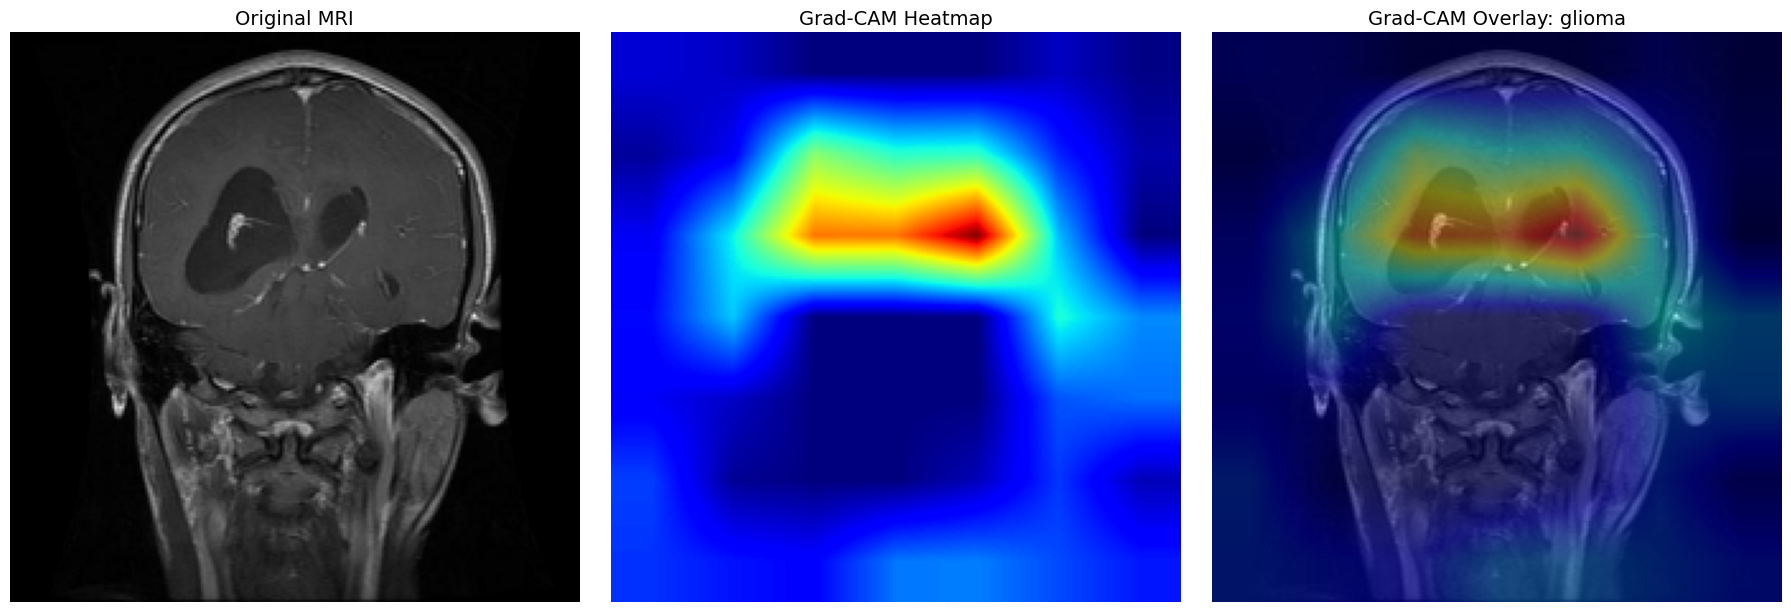

### Regional Grad-CAM Summary

- **Upper Third:** 0.1814

- **Middle Third:** 0.2325

- **Lower Third:** 0.1200

## Groq LLM Explanation

**1. Predicted class and its score**  
The model predicts **glioma** with a score of **0.8995**.

**2. Difference from the second‑ranked class**  
The next highest class is **meningioma** with a score of **0.1000**.  
The score gap is **0.7995**, showing a large separation between the glioma score and the meningioma score.

**3. Image third with the highest mean Grad‑CAM activation**  
The **middle third** of the image has the highest mean Grad‑CAM activation (0.2325), followed by the upper third (0.1814) and the lower third (0.1200).

**4. What Grad‑CAM can and cannot establish**  

*Can* – Grad‑CAM highlights regions that contributed most to the model’s glioma score. The middle third contributed the most on average.  

*Cannot* – Grad‑CAM does not prove that a tumor is present, nor does it locate the exact tumor boundaries or identify specific pathological features. It only reflects the model’s internal attention, not clinical truth.

**5. Alternative class and model limitations**  

The only plausible alternative from the output is **meningioma**, but its score (0.10) is far lower than the glioma score, indicating the model is much less confident about that class.  

Limitations to note:  
- Scores are not calibrated probabilities; they reflect relative confidence, not clinical certainty.  
- The large score gap does not guarantee a correct diagnosis.  
- Grad‑CAM summaries are coarse (upper/middle/lower thirds) and cannot replace detailed radiologic assessment.  

These points illustrate how the model’s output can be interpreted for research, while emphasizing that further clinical validation is required.


---
### Research limitations

- This output is an experimental model prediction, not a medical diagnosis.
- Model scores are not necessarily calibrated clinical probabilities.
- Grad-CAM indicates regions influential to a class score; it does not
  prove tumor presence or identify exact tumor boundaries.
- Performance must be evaluated on the untouched test dataset before
  reporting final research metrics.


Final Explainable AI panel generated successfully.


In [ ]:

# ============================================================
# FINAL EXPLAINABLE AI PANEL
# ResNet50 + Grad-CAM + Groq LLM
# ============================================================

import json
import numpy as np
import matplotlib.pyplot as plt
import cv2

from PIL import Image
from IPython.display import display, Markdown

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

GROQ_MODEL = "openai/gpt-oss-120b"
IMAGE_PATH = val_paths[0]  # Change index to inspect another validation MRI

# ------------------------------------------------------------
# 2. Generate prediction and Grad-CAM
# ------------------------------------------------------------

image, heatmap, predicted_index, probabilities = make_gradcam(IMAGE_PATH)

scores = np.asarray(probabilities, dtype=float).reshape(-1)

if len(scores) != len(CLASSES):
    raise ValueError(
        f"Expected {len(CLASSES)} class scores, got {len(scores)}."
    )

if not np.all(np.isfinite(scores)):
    raise ValueError("Model produced invalid prediction scores.")

ranking = np.argsort(scores)[::-1]
predicted_index = int(np.argmax(scores))
predicted_class = CLASSES[predicted_index]

second_index = int(ranking[1])
second_class = CLASSES[second_index]

# ------------------------------------------------------------
# 3. Prepare MRI and heatmap for visualization
# ------------------------------------------------------------

image_array = np.asarray(image)

# Convert grayscale MRI to RGB if required
if image_array.ndim == 2:
    image_rgb = cv2.cvtColor(
        np.clip(image_array, 0, 255).astype(np.uint8),
        cv2.COLOR_GRAY2RGB
    )
elif image_array.ndim == 3 and image_array.shape[-1] == 1:
    image_rgb = cv2.cvtColor(
        np.clip(image_array[..., 0], 0, 255).astype(np.uint8),
        cv2.COLOR_GRAY2RGB
    )
else:
    image_rgb = np.clip(image_array[..., :3], 0, 255).astype(np.uint8)

heatmap = np.asarray(heatmap).squeeze()
heatmap = np.maximum(heatmap, 0)

if heatmap.max() > 0:
    heatmap = heatmap / heatmap.max()

heatmap_resized = cv2.resize(
    heatmap.astype(np.float32),
    (image_rgb.shape[1], image_rgb.shape[0])
)

colored_heatmap = cv2.applyColorMap(
    np.uint8(255 * heatmap_resized),
    cv2.COLORMAP_JET
)
colored_heatmap = cv2.cvtColor(
    colored_heatmap, cv2.COLOR_BGR2RGB
)

overlay = cv2.addWeighted(
    image_rgb, 0.60,
    colored_heatmap, 0.40,
    0
)

# ------------------------------------------------------------
# 4. Calculate regional Grad-CAM statistics
# ------------------------------------------------------------

height = heatmap_resized.shape[0]
third = height // 3

regions = {
    "upper third": heatmap_resized[:third, :],
    "middle third": heatmap_resized[third:2 * third, :],
    "lower third": heatmap_resized[2 * third:, :]
}

regional_means = {
    name: float(np.mean(region))
    for name, region in regions.items()
    if region.size > 0
}

# ------------------------------------------------------------
# 5. Build evidence for Groq
# ------------------------------------------------------------

evidence = {
    "predicted_class": predicted_class,
    "top_class_score": round(float(scores[predicted_index]), 4),
    "second_class": second_class,
    "second_class_score": round(float(scores[second_index]), 4),
    "score_gap": round(
        float(scores[predicted_index] - scores[second_index]), 4
    ),
    "class_scores": {
        CLASSES[int(i)]: round(float(scores[i]), 4)
        for i in ranking
    },
    "mean_gradcam_activation_by_image_region": {
        name: round(value, 4)
        for name, value in regional_means.items()
    }
}

# ------------------------------------------------------------
# 6. Generate complete LLM explanation
# ------------------------------------------------------------

SYSTEM_PROMPT = """
You explain an experimental brain MRI image-classification model.

Use only the supplied class scores and Grad-CAM regional measurements.
Do not diagnose the patient or invent tumor features, boundaries,
symptoms, anatomy, or facts that are not supplied.

Explain:
1. Predicted class and its score.
2. Difference from the second-ranked class.
3. Which image third has the highest mean Grad-CAM activation.
4. What Grad-CAM can and cannot establish.
5. Alternative class and model limitations.

Important:
- Model scores are not necessarily calibrated clinical probabilities.
- A score gap indicates separation between model scores, not clinical certainty.
- Regional means summarize activation in image thirds; they do not prove
  that a tumor is located there.
- Grad-CAM highlights regions influential to a class score; it does not
  establish tumor presence or boundaries.
- Do not claim to know the exact features that caused the prediction.
- Use simple English, concise headings, and complete sentences.
- Keep the explanation under 300 words.
"""

user_prompt = (
    "Explain this model output for a research demonstration.\n\n"
    "MODEL EVIDENCE:\n"
    + json.dumps(evidence, indent=2)
)

completion = client.chat.completions.create(
    model=GROQ_MODEL,
    messages=[
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_prompt}
    ],
    temperature=0.2,
    max_tokens=700
)

explanation = completion.choices[0].message.content

if not explanation:
    explanation = (
        "The model returned no text explanation. "
        "Please rerun this cell or check Groq availability."
    )

# ------------------------------------------------------------
# 7. Display the final report
# ------------------------------------------------------------

display(Markdown("# Explainable Brain MRI Classification"))
display(Markdown(
    "**Research prototype:** ResNet50 + Grad-CAM + Groq LLM"
))

display(Markdown(
    f"### Predicted class: `{predicted_class}`\n"
    f"**Model score:** {scores[predicted_index]:.4f}  \n"
    f"**Second-ranked class:** {second_class} "
    f"({scores[second_index]:.4f})  \n"
    f"**Score gap:** "
    f"{scores[predicted_index] - scores[second_index]:.4f}"
))

# Class scores bar chart
fig, ax = plt.subplots(figsize=(9, 4.5))

class_names = [CLASSES[int(i)] for i in ranking]
ranked_scores = [float(scores[i]) for i in ranking]

bars = ax.barh(class_names[::-1], ranked_scores[::-1])
ax.set_xlim(0, 1)
ax.set_xlabel("Model output score")
ax.set_title("Scores Across the Four Classes")
ax.grid(axis="x", alpha=0.25)

for bar, value in zip(bars, ranked_scores[::-1]):
    ax.text(
        min(value + 0.015, 0.92),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center"
    )

plt.show()

# Three-image visualization
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    constrained_layout=True
)

axes[0].imshow(image_rgb)
axes[0].set_title("Original MRI", fontsize=14)
axes[0].axis("off")

axes[1].imshow(heatmap_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap", fontsize=14)
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title(
    f"Grad-CAM Overlay: {predicted_class}",
    fontsize=14
)
axes[2].axis("off")

plt.show()

# Regional activation summary
display(Markdown("### Regional Grad-CAM Summary"))

for region_name, value in regional_means.items():
    display(Markdown(
        f"- **{region_name.title()}:** {value:.4f}"
    ))

# Full LLM explanation
display(Markdown("## Groq LLM Explanation"))
display(Markdown(explanation))

# Research disclaimer
display(Markdown("""
---
### Research limitations

- This output is an experimental model prediction, not a medical diagnosis.
- Model scores are not necessarily calibrated clinical probabilities.
- Grad-CAM indicates regions influential to a class score; it does not
  prove tumor presence or identify exact tumor boundaries.
- Performance must be evaluated on the untouched test dataset before
  reporting final research metrics.
"""))

print("Final Explainable AI panel generated successfully.")


In [ ]:

import os

TEST_DIR = "/content/brain_tumor_clean/Testing"

print("Test directory exists:", os.path.isdir(TEST_DIR))

for class_name in CLASSES:
    class_dir = os.path.join(TEST_DIR, class_name)
    count = len([
        f for f in os.listdir(class_dir)
        if os.path.isfile(os.path.join(class_dir, f))
    ]) if os.path.isdir(class_dir) else 0

    print(f"{class_name}: {count} images")


Test directory exists: True
glioma: 386 images
meningioma: 398 images
notumor: 400 images
pituitary: 400 images


Fine-tuned ResNet50 loaded successfully.
Found 1584 files belonging to 4 classes.
Class order: ['glioma', 'meningioma', 'notumor', 'pituitary']
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 199ms/step

FINAL TEST SET RESULTS — FINE-TUNED RESNET50
Test images       : 1584
Accuracy          : 0.8535 (85.35%)
Macro Precision   : 0.8535
Macro Recall      : 0.8523
Macro F1-score    : 0.8513
Weighted Precision: 0.8541
Weighted Recall   : 0.8535
Weighted F1-score : 0.8523

Classification Report:
              precision    recall  f1-score   support

      glioma     0.7949    0.7228    0.7571       386
  meningioma     0.7862    0.8040    0.7950       398
     notumor     0.8650    0.9775    0.9178       400
   pituitary     0.9679    0.9050    0.9354       400

    accuracy                         0.8535      1584
   macro avg     0.8535    0.8523    0.8513      1584
weighted avg     0.8541    0.8535    0.8523      1584



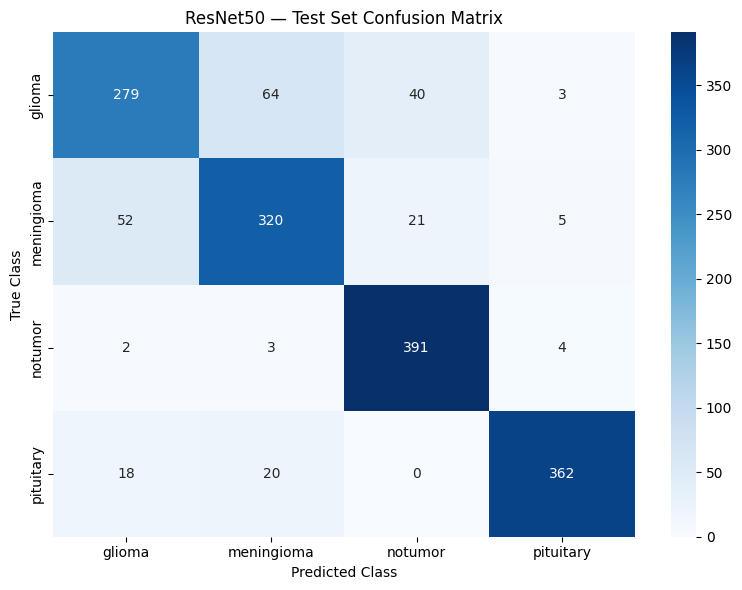


Metrics saved to /content/resnet50_test_results.json


In [ ]:

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)
from tensorflow import keras

# ============================================================
# 1. Configuration
# ============================================================

TEST_DIR = "/content/brain_tumor_clean/Testing"
MODEL_PATH = "/content/resnet50_finetuned.keras"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

# ============================================================
# 2. Load the saved fine-tuned model
# ============================================================

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"Model not found at {MODEL_PATH}. "
        "Save your trained model or provide the correct path."
    )

model = keras.models.load_model(MODEL_PATH)

print("Fine-tuned ResNet50 loaded successfully.")

# ============================================================
# 3. Build test dataset in a fixed class order
# ============================================================

test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    class_names=CLASSES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Class order:", test_ds.class_names)

# IMPORTANT:
# Do not add Rescaling(1./255) here unless your saved model
# requires it. The saved model should contain its own
# preprocessing layer if that is how it was trained.

# ============================================================
# 4. Collect true labels and model predictions
# ============================================================

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

assert len(y_true) == 1584, f"Expected 1584 test images, got {len(y_true)}"
assert y_prob.shape == (1584, 4), f"Unexpected prediction shape: {y_prob.shape}"

# ============================================================
# 5. Calculate final metrics
# ============================================================

accuracy = accuracy_score(y_true, y_pred)

precision_macro = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
recall_macro = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
f1_macro = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

precision_weighted = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)
recall_weighted = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)
f1_weighted = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

print("\n" + "=" * 60)
print("FINAL TEST SET RESULTS — FINE-TUNED RESNET50")
print("=" * 60)
print(f"Test images       : {len(y_true)}")
print(f"Accuracy          : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision   : {precision_macro:.4f}")
print(f"Macro Recall      : {recall_macro:.4f}")
print(f"Macro F1-score    : {f1_macro:.4f}")
print(f"Weighted Precision: {precision_weighted:.4f}")
print(f"Weighted Recall   : {recall_weighted:.4f}")
print(f"Weighted F1-score : {f1_weighted:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(CLASSES)),
    target_names=CLASSES,
    digits=4,
    zero_division=0
))

# ============================================================
# 6. Confusion matrix
# ============================================================

cm = confusion_matrix(
    y_true, y_pred, labels=np.arange(len(CLASSES))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.title("ResNet50 — Test Set Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

# ============================================================
# 7. Save evaluation metrics for research reporting
# ============================================================

import json

results = {
    "model": "Fine-tuned ResNet50",
    "test_images": int(len(y_true)),
    "class_order": CLASSES,
    "accuracy": float(accuracy),
    "macro_precision": float(precision_macro),
    "macro_recall": float(recall_macro),
    "macro_f1": float(f1_macro),
    "weighted_precision": float(precision_weighted),
    "weighted_recall": float(recall_weighted),
    "weighted_f1": float(f1_weighted),
    "confusion_matrix": cm.tolist()
}

with open("/content/resnet50_test_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("\nMetrics saved to /content/resnet50_test_results.json")


In [ ]:

import tensorflow as tf

print("Available Keras models:\n")

found = False

for name, obj in list(globals().items()):
    if isinstance(obj, tf.keras.Model):
        found = True
        print(f"Variable name : {name}")
        print(f"Model name    : {obj.name}")
        print(f"Parameters    : {obj.count_params():,}")
        print(f"Output shape  : {obj.output_shape}")
        print("-" * 40)

if not found:
    print("No Keras model variables found in the current runtime.")


Available Keras models:

Variable name : model
Model name    : functional_1
Parameters    : 23,850,500
Output shape  : (None, 4)
----------------------------------------
Variable name : base_model
Model name    : resnet50
Parameters    : 23,587,712
Output shape  : (None, 7, 7, 2048)
----------------------------------------
Variable name : resnet_model
Model name    : functional_1
Parameters    : 23,850,500
Output shape  : (None, 4)
----------------------------------------
Variable name : backbone
Model name    : resnet50
Parameters    : 23,587,712
Output shape  : (None, 7, 7, 2048)
----------------------------------------
Variable name : grad_model
Model name    : functional_4
Parameters    : 23,850,500
Output shape  : [(None, 7, 7, 2048), (None, 4)]
----------------------------------------
Variable name : backbone_cam
Model name    : functional_3
Parameters    : 23,587,712
Output shape  : [(None, 7, 7, 2048), (None, 7, 7, 2048)]
----------------------------------------


In [ ]:

import os

search_roots = ["/content"]

print("Searching for saved model files...\n")

found_files = []

for root_dir in search_roots:
    for current_dir, dirs, files in os.walk(root_dir):
        # Skip large dataset folders
        dirs[:] = [
            d for d in dirs
            if d not in ["brain_tumor", "brain_tumor_clean"]
        ]

        for filename in files:
            lower_name = filename.lower()

            if (
                lower_name.endswith((".keras", ".h5", ".hdf5"))
                or "checkpoint" in lower_name
            ):
                path = os.path.join(current_dir, filename)
                found_files.append(path)
                print(path)

if not found_files:
    print("No saved model files found in /content.")


Searching for saved model files...

/content/resnet50_finetuned.keras


In [ ]:

# Check whether Custom CNN architecture or history still exists

for var_name in ["cnn_model", "custom_cnn", "baseline_model",
                 "history", "baseline_history", "model_cnn"]:
    if var_name in globals():
        obj = globals()[var_name]
        print(f"\nFound: {var_name}")
        print("Type:", type(obj))

        if hasattr(obj, "count_params"):
            print("Parameters:", f"{obj.count_params():,}")

        if hasattr(obj, "history"):
            print("History metrics:", list(obj.history.keys()))

        elif isinstance(obj, dict):
            print("Available keys:", list(obj.keys()))

print("\nCheck completed.")



Found: history
Type: <class 'keras.src.callbacks.history.History'>
History metrics: ['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate']

Check completed.


In [ ]:

print("Training history summary")
print("=" * 40)

for key, values in history.history.items():
    if values:
        print(f"{key}:")
        print(f"  Epochs recorded: {len(values)}")
        print(f"  First value: {values[0]:.4f}")
        print(f"  Last value:  {values[-1]:.4f}")
        print(f"  Best value:  {max(values) if 'accuracy' in key else min(values):.4f}")


Training history summary
accuracy:
  Epochs recorded: 15
  First value: 0.4209
  Last value:  0.8321
  Best value:  0.8321
loss:
  Epochs recorded: 15
  First value: 1.1774
  Last value:  0.4258
  Best value:  0.4258
val_accuracy:
  Epochs recorded: 15
  First value: 0.5764
  Last value:  0.8564
  Best value:  0.8600
val_loss:
  Epochs recorded: 15
  First value: 0.9884
  Last value:  0.3791
  Best value:  0.3732
learning_rate:
  Epochs recorded: 15
  First value: 0.0010
  Last value:  0.0005
  Best value:  0.0005


Training Custom CNN. This may take several minutes...
Epoch 1/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 23s 101ms/step - accuracy: 0.3947 - loss: 1.2127 - val_accuracy: 0.5654 - val_loss: 1.0557 - learning_rate: 0.0010
Epoch 2/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 11s 70ms/step - accuracy: 0.5846 - loss: 0.9859 - val_accuracy: 0.6952 - val_loss: 0.8544 - learning_rate: 0.0010
Epoch 3/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 71ms/step - accuracy: 0.6668 - loss: 0.8331 - val_accuracy: 0.7569 - val_loss: 0.6753 - learning_rate: 0.0010
Epoch 4/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - accuracy: 0.6974 - loss: 0.7437 - val_accuracy: 0.7615 - val_loss: 0.6471 - learning_rate: 0.0010
Epoch 5/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.7481 - loss: 0.6538 - val_accuracy: 0.7993 - val_loss: 0.5456 - learning_rate: 0.0010
Epoch 6/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 18s 71ms/step - accuracy: 0.7481 - loss: 0.6274 - val_accuracy: 0.8020 - val_loss: 0.5016 - learning_rate: 0.0010
Epoch 7/15
136/136 ━━

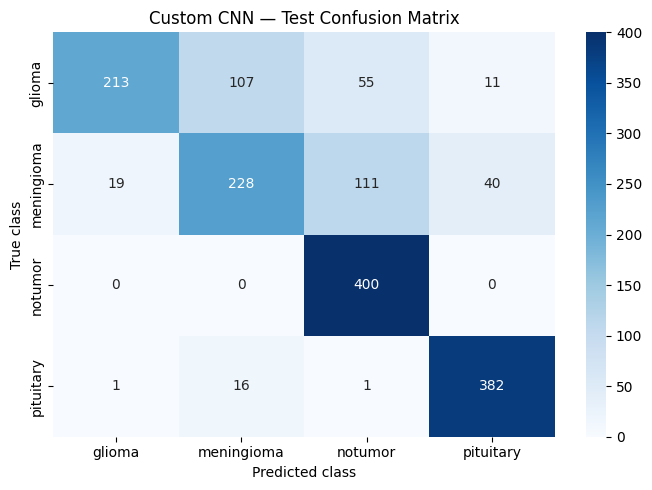


Evaluating Fine-tuned ResNet50...
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 184ms/step

Fine-tuned ResNet50
Accuracy: 0.8535
Macro F1: 0.8513
              precision    recall  f1-score   support

      glioma     0.7949    0.7228    0.7571       386
  meningioma     0.7862    0.8040    0.7950       398
     notumor     0.8650    0.9775    0.9178       400
   pituitary     0.9679    0.9050    0.9354       400

    accuracy                         0.8535      1584
   macro avg     0.8535    0.8523    0.8513      1584
weighted avg     0.8541    0.8535    0.8523      1584



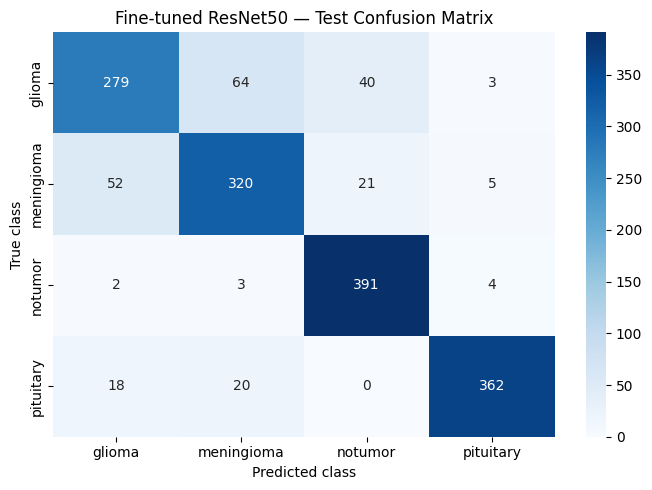


FINAL TEST COMPARISON
{
  "Custom CNN": {
    "test_images": 1584,
    "accuracy": 0.7720959595959596,
    "macro_precision": 0.7878550504761819,
    "macro_recall": 0.7699194482776577,
    "macro_f1": 0.7603715828990573,
    "weighted_f1": 0.7612007665079368
  },
  "Fine-tuned ResNet50": {
    "test_images": 1584,
    "accuracy": 0.8535353535353535,
    "macro_precision": 0.8535178168507163,
    "macro_recall": 0.8523295069909131,
    "macro_f1": 0.8513488554561813,
    "weighted_f1": 0.8522527638816347
  }
}

Saved files:
/content/custom_cnn_baseline.keras
/content/resnet50_finetuned.keras
/content/model_comparison_test_results.json


In [ ]:

import os
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
SEED = 42
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
TEST_DIR = "/content/brain_tumor_clean/Testing"
CNN_PATH = "/content/custom_cnn_baseline.keras"
RESNET_PATH = "/content/resnet50_finetuned.keras"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

tf.keras.utils.set_random_seed(SEED)

# Confirm original training datasets are available
assert "train_ds" in globals(), "train_ds missing. Run the dataset preparation cell."
assert "val_ds" in globals(), "val_ds missing. Run the dataset preparation cell."

# --------------------------------------------------
# 2. Rebuild the notebook's original Custom CNN
# --------------------------------------------------
custom_cnn = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.30),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(4, activation="softmax")
])

custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

print("Training Custom CNN. This may take several minutes...")
cnn_history = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

# Save weights and architecture together
custom_cnn.save(CNN_PATH)
print("\nCustom CNN saved:", CNN_PATH)

# Save training history
with open("/content/custom_cnn_history.json", "w") as f:
    json.dump(
        {k: [float(v) for v in values]
         for k, values in cnn_history.history.items()},
        f, indent=2
    )

# --------------------------------------------------
# 3. Load saved ResNet50
# --------------------------------------------------
if not os.path.exists(RESNET_PATH):
    raise FileNotFoundError(
        "Saved ResNet50 not found. Save resnet_model first."
    )

resnet = keras.models.load_model(RESNET_PATH)
print("ResNet50 loaded:", RESNET_PATH)

# --------------------------------------------------
# 4. Build fixed-order test dataset
# --------------------------------------------------
raw_test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    class_names=CLASSES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Custom CNN was trained on images scaled to [0, 1].
# ResNet50 has its own Rescaling layer, so pass [0, 255] images.
cnn_test_ds = raw_test_ds.map(
    lambda x, y: (tf.cast(x, tf.float32) / 255.0, y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

# Collect true labels in the same deterministic order
y_true = np.concatenate([y.numpy() for _, y in raw_test_ds])

# --------------------------------------------------
# 5. Evaluate both models on the same test set
# --------------------------------------------------
models_to_evaluate = {
    "Custom CNN": (custom_cnn, cnn_test_ds),
    "Fine-tuned ResNet50": (resnet, raw_test_ds)
}

all_results = {}

for model_name, (model_obj, dataset) in models_to_evaluate.items():
    print(f"\nEvaluating {model_name}...")
    probs = model_obj.predict(dataset, verbose=1)
    preds = np.argmax(probs, axis=1)

    metrics = {
        "test_images": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, preds)),
        "macro_precision": float(precision_score(
            y_true, preds, average="macro", zero_division=0
        )),
        "macro_recall": float(recall_score(
            y_true, preds, average="macro", zero_division=0
        )),
        "macro_f1": float(f1_score(
            y_true, preds, average="macro", zero_division=0
        )),
        "weighted_f1": float(f1_score(
            y_true, preds, average="weighted", zero_division=0
        )),
        "classification_report": classification_report(
            y_true, preds,
            labels=list(range(len(CLASSES))),
            target_names=CLASSES,
            output_dict=True,
            zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            y_true, preds,
            labels=list(range(len(CLASSES)))
        ).tolist()
    }

    all_results[model_name] = metrics

    print(f"\n{model_name}")
    print(f"Accuracy: {metrics['accuracy']:.4f}")
    print(f"Macro F1: {metrics['macro_f1']:.4f}")
    print(classification_report(
        y_true, preds,
        labels=list(range(len(CLASSES))),
        target_names=CLASSES,
        digits=4,
        zero_division=0
    ))

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        metrics["confusion_matrix"],
        annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASSES, yticklabels=CLASSES
    )
    plt.title(f"{model_name} — Test Confusion Matrix")
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.tight_layout()
    safe_name = model_name.lower().replace(" ", "_").replace("-", "")
    plt.savefig(
        f"/content/{safe_name}_test_confusion_matrix.png",
        dpi=200, bbox_inches="tight"
    )
    plt.show()

# --------------------------------------------------
# 6. Save comparison results
# --------------------------------------------------
summary = {
    name: {
        key: values[key]
        for key in [
            "test_images", "accuracy", "macro_precision",
            "macro_recall", "macro_f1", "weighted_f1"
        ]
    }
    for name, values in all_results.items()
}

with open("/content/model_comparison_test_results.json", "w") as f:
    json.dump(all_results, f, indent=2)

print("\nFINAL TEST COMPARISON")
print(json.dumps(summary, indent=2))
print("\nSaved files:")
print(CNN_PATH)
print(RESNET_PATH)
print("/content/model_comparison_test_results.json")


In [ ]:

import os
import zipfile
from google.colab import files

files_to_save = [
    "/content/custom_cnn_baseline.keras",
    "/content/resnet50_finetuned.keras",
    "/content/model_comparison_test_results.json",
    "/content/custom_cnn_history.json",
    "/content/resnet50_test_results.json",
]

zip_path = "/content/BrainTumorAI_Project_Models.zip"

missing = [p for p in files_to_save if not os.path.exists(p)]
if missing:
    print("Files not found:")
    for p in missing:
        print(" -", p)

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in files_to_save:
        if os.path.exists(path):
            z.write(path, arcname=os.path.basename(path))
            print("Packed:", os.path.basename(path))

print("\nDownload your model package:")
files.download(zip_path)


Packed: custom_cnn_baseline.keras
Packed: resnet50_finetuned.keras
Packed: model_comparison_test_results.json
Packed: custom_cnn_history.json
Packed: resnet50_test_results.json

Download your model package:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("history_finetune" in globals())

False


In [ ]:
print([k for k in globals() if "history" in k.lower()])

[]
